<a href="https://colab.research.google.com/github/KrithikChidM/PrmlLab/blob/main/Lab7/code.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Qn1

In [ ]:
import math
import random
import numpy as np
import matplotlib.pyplot as plt

random.seed(42)

n = 5000
K = 3
weights = np.array([0.5, 0.3, 0.2])

In [ ]:
means = np.array([[-1.0, -3.5], [0.0, 0.0], [1.0, 3.5]])
means_2 = means + np.array([4.0, 0.0])
class_means = [means, means_2]

covariances = [
    np.array([[1.0, 0.6], [0.6, 1.0]]),
    np.eye(2),
    np.diag([1.5, 0.5])
]

covariances_2 = [
    np.array([[1.0, -0.6], [-0.6, 1.0]]),
    np.eye(2),
    np.array([[1.5, -0.5], [-0.5, 0.5]])
]

class_covariances = [covariances, covariances_2]

covariance_names = [
    ["Full (+tilt)", "Isotropic", "Diagonal"],
    ["Full (-tilt)", "Isotropic", "Full (-tilt)"]
]

In [ ]:
def uniform():
    return max(random.random(), 1e-12)

def box_muller():
    u1 = uniform()
    u2 = uniform()
    r = math.sqrt(-2 * math.log(u1))
    theta = 2 * math.pi * u2
    z1 = r * math.cos(theta)
    z2 = r * math.sin(theta)
    return z1, z2

In [ ]:
def generate_component(mean, C):
    z1, z2 = box_muller()

    a, b = C[0]
    c, d = C[1]

    l11 = math.sqrt(a)
    l21 = c / l11
    l22 = math.sqrt(max(d - l21*l21, 0.0))

    x1 = mean[0] + l11*z1
    x2 = mean[1] + l21*z1 + l22*z2

    return [x1, x2]

In [ ]:
def generate_gmm_data(means, covariances, weights, n):
    X = []
    component_labels = []

    for _ in range(n):
        u = uniform()

        if u < weights[0]:
            k = 0
        elif u < weights[0] + weights[1]:
            k = 1
        else:
            k = 2

        x = generate_component(means[k], covariances[k])

        X.append(x)
        component_labels.append(k)

    return np.array(X), np.array(component_labels)

In [ ]:
class_data = []
class_component_labels = []

for cls in range(2):
    X, component_labels = generate_gmm_data(
        class_means[cls],
        class_covariances[cls],
        weights,
        n
    )

    class_data.append(X)
    class_component_labels.append(component_labels)

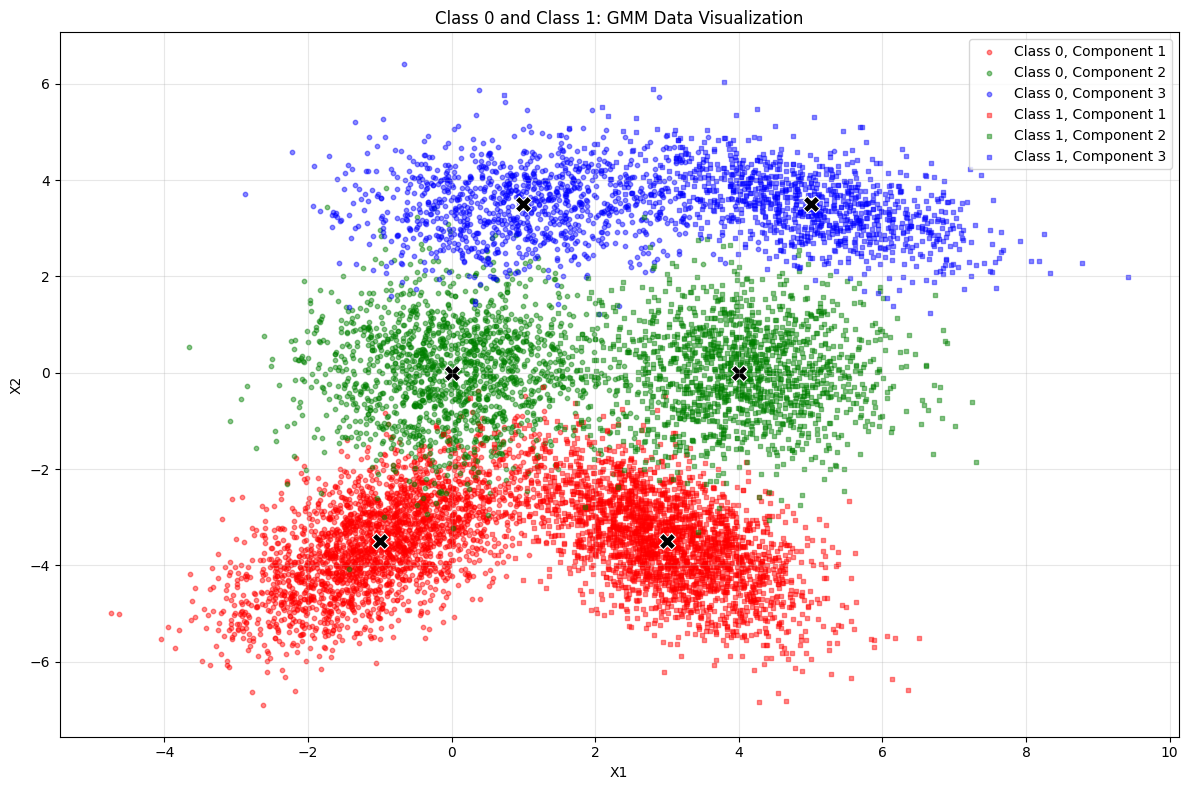

In [ ]:
plt.figure(figsize=(12, 8))

colors = ["red", "green", "blue"]
markers = ["o", "s"]

for cls in range(2):
    X = class_data[cls]
    labels = class_component_labels[cls]

    for k in range(K):
        points = X[labels == k]
        plt.scatter(
            points[:, 0], points[:, 1],
            color=colors[k], marker=markers[cls],
            s=10, alpha=0.45,
            label=f"Class {cls}, Component {k + 1}"
        )

    for k in range(K):
        plt.scatter(
            class_means[cls][k][0], class_means[cls][k][1],
            color="black", marker="X", s=140,
            edgecolors="white", linewidths=0.8
        )

plt.xlabel("X1")
plt.ylabel("X2")
plt.title("Class 0 and Class 1: GMM Data Visualization")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
train_data = []
test_data = []

rng = np.random.default_rng(44)
train_end = int(0.8 * n)

for samples in class_data:
    shuffled = samples[np.random.default_rng().permutation(n)]
    train_data.append(shuffled[:train_end])
    test_data.append(shuffled[train_end:])

In [ ]:
class GMM:
    def __init__(self, K, max_iterations=100, tolerance=1e-5):
        self.K = K
        self.max_iterations = max_iterations
        self.tolerance = tolerance

    def gaussian_density(self, X, mean, covariance):
        dimension = X.shape[1]

        a = covariance[0, 0]
        b = covariance[0, 1]
        c = covariance[1, 0]
        d = covariance[1, 1]

        det = a * d - b * c

        if det <= 1e-12:
            return np.zeros(len(X))

        dx = X[:, 0] - mean[0]
        dy = X[:, 1] - mean[1]

        q = (d * dx**2 - (b + c) * dx * dy + a * dy**2) / det

        return np.exp(-0.5 * q) / (
            (2 * math.pi) ** (dimension / 2) * math.sqrt(det)
        )

    def initialize(self, X):
        self.means = np.array(random.sample(list(X), self.K))

        self.weights = np.ones(self.K) / self.K

        self.covariances = []

        for i in range(self.K):
            self.covariances.append(np.eye(X.shape[1]))

        self.covariances = np.array(self.covariances)

    def expectation(self, X):
        responsibilities = np.zeros((len(X), self.K))

        for k in range(self.K):
            responsibilities[:, k] = (
                self.weights[k] *
                self.gaussian_density(
                    X, self.means[k], self.covariances[k]
                )
            )

        total = np.sum(responsibilities, axis=1, keepdims=True)
        total = np.maximum(total, 1e-300)

        responsibilities = responsibilities / total

        return responsibilities

    def maximization(self, X, responsibilities):
        Nk = np.sum(responsibilities, axis=0)
        Nk = np.maximum(Nk, 1e-10)

        self.weights = Nk / len(X)

        self.means = (
            responsibilities.T @ X
        ) / Nk[:, None]

        self.covariances = []

        for k in range(self.K):
            difference = X - self.means[k]

            covariance = (
                responsibilities[:, k][:, None] * difference
            ).T @ difference / Nk[k]

            covariance += np.eye(X.shape[1]) * 1e-6

            self.covariances.append(covariance)

        self.covariances = np.array(self.covariances)

    def fit(self, X):
        self.initialize(X)

        previous_log_likelihood = -float("inf")

        for iteration in range(self.max_iterations):
            responsibilities = self.expectation(X)

            self.maximization(X, responsibilities)

            likelihood = np.zeros(len(X))

            for k in range(self.K):
                likelihood += (
                    self.weights[k] *
                    self.gaussian_density(
                        X, self.means[k], self.covariances[k]
                    )
                )

            log_likelihood = np.sum(
                np.log(np.maximum(likelihood, 1e-300))
            )

            if abs(log_likelihood - previous_log_likelihood) < self.tolerance:
                break

            previous_log_likelihood = log_likelihood

    def predict_density(self, X):
        density = np.zeros(len(X))

        for k in range(self.K):
            density += (
                self.weights[k] *
                self.gaussian_density(
                    X, self.means[k], self.covariances[k]
                )
            )

        return density

    def predict(self, X):
        return np.log(np.maximum(self.predict_density(X), 1e-300))

In [ ]:
gmm_models = []

for cls in range(2):
    model = GMM(K=K, max_iterations=200)
    model.fit(train_data[cls])

    gmm_models.append(model)

    print(f"\nClass {cls} GMM Model")
    print("Weights:", model.weights)
    print("Means:\n", model.means)
    print("Covariances:\n", model.covariances)


Class 0 GMM Model
Weights: [0.30146887 0.49243937 0.20609176]
Means:
 [[ 0.00541461  0.026117  ]
 [-0.99353148 -3.51424585]
 [ 1.02574664  3.49726011]]
Covariances:
 [[[1.02465693 0.05718701]
  [0.05718701 1.05495558]]

 [[0.98340169 0.60997597]
  [0.60997597 1.0420455 ]]

 [[1.52688346 0.0281757 ]
  [0.0281757  0.51656337]]]

Class 1 GMM Model
Weights: [0.28763245 0.20379107 0.50857648]
Means:
 [[ 4.04580562  0.02846296]
 [ 4.94943771  3.4949598 ]
 [ 3.01086462 -3.48900918]]
Covariances:
 [[[ 1.11842946 -0.00156449]
  [-0.00156449  0.95747166]]

 [[ 1.53342316 -0.49894656]
  [-0.49894656  0.51305042]]

 [[ 0.94016063 -0.5430826 ]
  [-0.5430826   0.95412445]]]


In [ ]:
actual_labels = []
predicted_labels = []

for cls in range(2):
    for point in test_data[cls]:
        point = np.array(point).reshape(1, -1)

        density0 = gmm_models[0].predict(point)[0]
        density1 = gmm_models[1].predict(point)[0]

        predicted_class = 0 if density0 > density1 else 1

        actual_labels.append(cls)
        predicted_labels.append(predicted_class)

actual_labels = np.array(actual_labels)
predicted_labels = np.array(predicted_labels)

correct = np.sum(actual_labels == predicted_labels)
total = len(actual_labels)

print("Total test samples:", total)
print("Correct predictions:", correct)
print("Incorrect predictions:", total - correct)
print(f"Classification Accuracy: {100 * correct / total:.2f}%")

Total test samples: 2000
Correct predictions: 1946
Incorrect predictions: 54
Classification Accuracy: 97.30%


In [ ]:
confusion_matrix = np.zeros((2, 2), dtype=int)

for actual, predicted in zip(actual_labels, predicted_labels):
    confusion_matrix[actual][predicted] += 1

print("Confusion Matrix:")
print(confusion_matrix)

print("\nRows = Actual Classes")
print("Columns = Predicted Classes")
print("             Predicted 0    Predicted 1")
print("Actual 0       ", confusion_matrix[0, 0], "          ", confusion_matrix[0, 1])
print("Actual 1       ", confusion_matrix[1, 0], "          ", confusion_matrix[1, 1])

Confusion Matrix:
[[977  23]
 [ 31 969]]

Rows = Actual Classes
Columns = Predicted Classes
             Predicted 0    Predicted 1
Actual 0        977            23
Actual 1        31            969


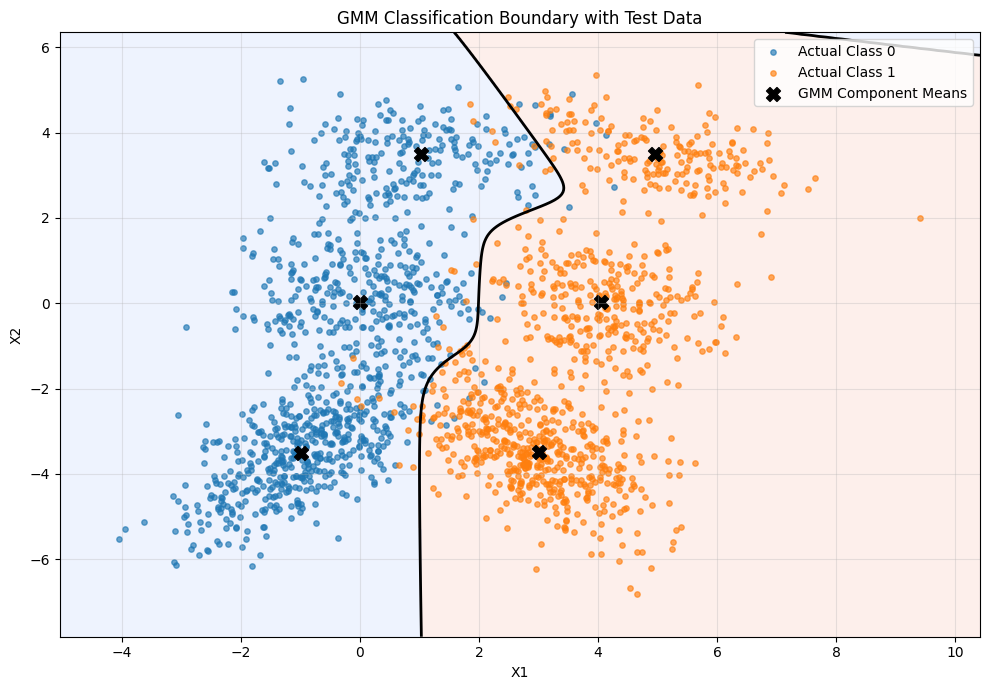

In [ ]:
plt.figure(figsize=(10, 7))

all_test = np.vstack(test_data)

x_min = all_test[:, 0].min() - 1
x_max = all_test[:, 0].max() + 1
y_min = all_test[:, 1].min() - 1
y_max = all_test[:, 1].max() + 1

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 300),
    np.linspace(y_min, y_max, 300)
)

grid = np.column_stack((xx.ravel(), yy.ravel()))

density0 = np.exp(gmm_models[0].predict(grid))
density1 = np.exp(gmm_models[1].predict(grid))

Z = (density1 > density0).astype(int).reshape(xx.shape)

plt.contourf(
    xx, yy, Z,
    levels=[-0.5, 0.5, 1.5],
    alpha=0.15,
    cmap="coolwarm"
)

plt.contour(
    xx, yy,
    density0.reshape(xx.shape) - density1.reshape(xx.shape),
    levels=[0],
    colors="black",
    linewidths=2
)

for cls in range(2):
    X = test_data[cls]

    plt.scatter(
        X[:, 0], X[:, 1],
        s=15,
        alpha=0.65,
        label=f"Actual Class {cls}"
    )

plt.scatter(
    np.vstack([model.means for model in gmm_models])[:, 0],
    np.vstack([model.means for model in gmm_models])[:, 1],
    color="black",
    marker="X",
    s=100,
    label="GMM Component Means"
)

plt.xlabel("X1")
plt.ylabel("X2")
plt.title("GMM Classification Boundary with Test Data")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

#Qn2

In [7]:
from google.colab import drive
drive.mount('/content/drive')

import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.image as mpimg

Mounted at /content/drive


In [14]:
base_path = '/content/drive/MyDrive/Krithik SNU/HAM/teams/TEAM_7/train'

digits = [6, 3, 8]
K_values = [3,5,9]

max_iter = 70
eps = 1e-10

In [3]:
class RandomGenerator:

    def __init__(self, seed=42):
        self.seed = seed
        self.a = 1664525
        self.c = 1013904223
        self.m = 2**32

    def random(self):
        self.seed = (self.a * self.seed + self.c) % self.m
        return self.seed / self.m

    def randint(self, low, high):
        return low + int(self.random() * (high - low + 1))

    def shuffle(self, data):
        for i in range(len(data) - 1, 0, -1):
            j = self.randint(0, i)
            data[i], data[j] = data[j], data[i]
        return data

    def choice(self, data, size, replace=False):

        if not replace and size > len(data):
            raise ValueError("Sample size exceeds population")

        if replace:
            result = []
            for i in range(size):
                index = self.randint(0, len(data) - 1)
                result.append(data[index])
        else:
            temp = list(data)
            self.shuffle(temp)
            result = temp[:size]

        return np.array(result)


rng = RandomGenerator(42)

In [8]:
def get_image_files(folder):

    extensions = ('.png', '.jpg', '.jpeg',
                  '.bmp', '.tif', '.tiff')

    files = []

    for root, dirs, filenames in os.walk(folder):
        for filename in filenames:
            if filename.lower().endswith(extensions):
                files.append(os.path.join(root, filename))

    return files


def load_image(filename):

    img = mpimg.imread(filename)

    if img.ndim == 3:
        img = img[:, :, :3].mean(axis=2)

    img = img.astype(np.float64)

    if img.max() > 1:
        img = img / 255.0

    h, w = img.shape

    rows = np.linspace(0, h - 1, 28).astype(int)
    cols = np.linspace(0, w - 1, 28).astype(int)

    img = img[np.ix_(rows, cols)]

    return img.reshape(784)

In [9]:
data = {}

for digit in digits:

    folder = os.path.join(base_path, str(digit))
    files = get_image_files(folder)

    print(f"\nDigit {digit}: Total images = {len(files)}")

    if len(files) < max(K_values):
        raise ValueError(f"Not enough images for digit {digit}")

    images = [load_image(f) for f in files]

    rng.shuffle(images)

    split = int(0.8 * len(images))

    data[digit] = {
        'development': np.array(images[:split]),
        'test': np.array(images[split:])
    }

    print("Development images:", split)
    print("Test images:", len(images) - split)


Digit 6: Total images = 4752
Development images: 3801
Test images: 951

Digit 3: Total images = 4886
Development images: 3908
Test images: 978

Digit 8: Total images = 4674
Development images: 3739
Test images: 935


In [10]:
train_data = {}
validation_data = {}
test_data = {}

for digit in digits:

    X = data[digit]['development']

    rng.shuffle(X)

    split = int(0.8 * len(X))

    train_data[digit] = X[:split]
    validation_data[digit] = X[split:]
    test_data[digit] = data[digit]['test']

    print(f"\nDigit {digit}")
    print("Training:", len(train_data[digit]))
    print("Validation:", len(validation_data[digit]))
    print("Testing:", len(test_data[digit]))


Digit 6
Training: 3040
Validation: 761
Testing: 951

Digit 3
Training: 3126
Validation: 782
Testing: 978

Digit 8
Training: 2991
Validation: 748
Testing: 935


In [11]:
def logsumexp(a, axis=1):

    m = np.max(a, axis=axis, keepdims=True)

    result = m + np.log(
        np.sum(np.exp(a - m), axis=axis, keepdims=True)
    )

    return result.squeeze(axis)

def log_gaussian_diag(X, means, variances):

    diff = X[:, None, :] - means[None, :, :]

    return -0.5 * (
        X.shape[1] * np.log(2 * np.pi)
        + np.sum(np.log(variances), axis=1)[None, :]
        + np.sum(
            diff ** 2 / variances[None, :, :],
            axis=2
        )
    )


In [12]:
class GMM:

    def __init__(self, K, max_iter=30):

        self.K = K
        self.max_iter = max_iter

        self.weights = None
        self.means = None
        self.variances = None

        self.log_likelihood_history = []

    def fit(self, X, label=""):

        n, d = X.shape

        self.means = rng.choice(
            X,
            self.K,
            replace=False
        )

        global_var = np.var(X, axis=0) + 1e-4

        self.variances = np.tile(
            global_var,
            (self.K, 1)
        )

        self.weights = np.ones(self.K) / self.K

        previous_ll = -np.inf

        for iteration in range(self.max_iter):

            # E-step
            log_prob = log_gaussian_diag(
                X,
                self.means,
                self.variances
            )

            log_joint = (
                log_prob +
                np.log(self.weights + eps)[None, :]
            )

            log_norm = logsumexp(log_joint)

            responsibilities = np.exp(
                log_joint - log_norm[:, None]
            )

            # M-step
            Nk = responsibilities.sum(axis=0) + eps

            self.weights = Nk / n

            self.means = (
                responsibilities.T @ X
            ) / Nk[:, None]

            for k in range(self.K):

                diff = X - self.means[k]

                self.variances[k] = (
                    responsibilities[:, k, None] * diff ** 2
                ).sum(axis=0) / Nk[k]

            self.variances = np.maximum(
                self.variances,
                1e-4
            )

            # Calculate log likelihood
            current_ll = np.sum(log_norm)

            self.log_likelihood_history.append(current_ll)

            print(
                f"{label} | Iteration {iteration + 1}/{self.max_iter}"
                f" | Log Likelihood: {current_ll:.4f}"
            )

            if abs(current_ll - previous_ll) < 1e-4:
                print("Converged!")
                break

            previous_ll = current_ll

        # Plot log likelihood after training
        plt.figure(figsize=(7, 4))

        plt.plot(
            range(1, len(self.log_likelihood_history) + 1),
            self.log_likelihood_history,
            marker='o'
        )

        plt.xlabel("Iteration")
        plt.ylabel("Log Likelihood")
        plt.title(f"{label} - Log Likelihood Convergence")

        plt.grid(True)
        plt.tight_layout()
        plt.show()

        return self

    def score_samples(self, X):

        log_prob = log_gaussian_diag(
            X,
            self.means,
            self.variances
        )

        log_joint = (
            log_prob +
            np.log(self.weights + eps)[None, :]
        )

        return logsumexp(log_joint)

    def predict_score(self, X):

        return np.mean(self.score_samples(X))



Selecting K for Digit 6

Training GMM: Digit 6, K=3
Digit 6, K=3 | Iteration 1/70 | Log Likelihood: 3093404.2354
Digit 6, K=3 | Iteration 2/70 | Log Likelihood: 4071015.7470
Digit 6, K=3 | Iteration 3/70 | Log Likelihood: 4302144.9859
Digit 6, K=3 | Iteration 4/70 | Log Likelihood: 4362288.8608
Digit 6, K=3 | Iteration 5/70 | Log Likelihood: 4394014.3090
Digit 6, K=3 | Iteration 6/70 | Log Likelihood: 4395824.9460
Digit 6, K=3 | Iteration 7/70 | Log Likelihood: 4397377.1912
Digit 6, K=3 | Iteration 8/70 | Log Likelihood: 4398216.8156
Digit 6, K=3 | Iteration 9/70 | Log Likelihood: 4398324.3503
Digit 6, K=3 | Iteration 10/70 | Log Likelihood: 4398516.7794
Digit 6, K=3 | Iteration 11/70 | Log Likelihood: 4399020.9049
Digit 6, K=3 | Iteration 12/70 | Log Likelihood: 4399432.9683
Digit 6, K=3 | Iteration 13/70 | Log Likelihood: 4399703.6181
Digit 6, K=3 | Iteration 14/70 | Log Likelihood: 4399756.3530
Digit 6, K=3 | Iteration 15/70 | Log Likelihood: 4399793.0844
Digit 6, K=3 | Iteration 1

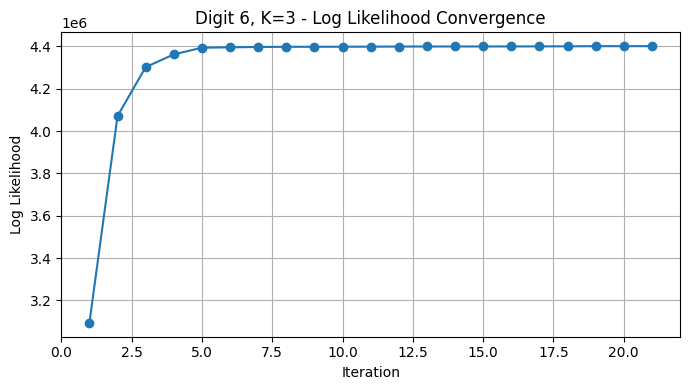

Validation Average Log Likelihood: 1377.3353

Training GMM: Digit 6, K=5
Digit 6, K=5 | Iteration 1/70 | Log Likelihood: 3530444.9810
Digit 6, K=5 | Iteration 2/70 | Log Likelihood: 4499069.5767
Digit 6, K=5 | Iteration 3/70 | Log Likelihood: 4745595.0681
Digit 6, K=5 | Iteration 4/70 | Log Likelihood: 4785855.2956
Digit 6, K=5 | Iteration 5/70 | Log Likelihood: 4828809.5246
Digit 6, K=5 | Iteration 6/70 | Log Likelihood: 4846848.6257
Digit 6, K=5 | Iteration 7/70 | Log Likelihood: 4851235.0639
Digit 6, K=5 | Iteration 8/70 | Log Likelihood: 4851964.0379
Digit 6, K=5 | Iteration 9/70 | Log Likelihood: 4853908.1384
Digit 6, K=5 | Iteration 10/70 | Log Likelihood: 4854196.3841
Digit 6, K=5 | Iteration 11/70 | Log Likelihood: 4854208.8871
Digit 6, K=5 | Iteration 12/70 | Log Likelihood: 4854208.9459
Digit 6, K=5 | Iteration 13/70 | Log Likelihood: 4854208.9547
Digit 6, K=5 | Iteration 14/70 | Log Likelihood: 4854208.9763
Digit 6, K=5 | Iteration 15/70 | Log Likelihood: 4854209.4023
Digit 

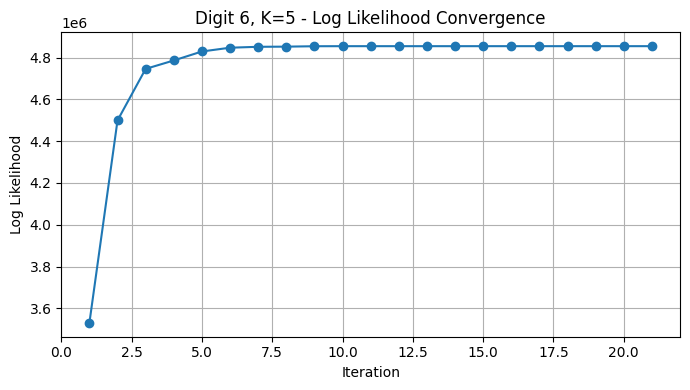

Validation Average Log Likelihood: 1533.7621

Training GMM: Digit 6, K=9
Digit 6, K=9 | Iteration 1/70 | Log Likelihood: 3546083.0889
Digit 6, K=9 | Iteration 2/70 | Log Likelihood: 4678814.9951
Digit 6, K=9 | Iteration 3/70 | Log Likelihood: 4967373.5060
Digit 6, K=9 | Iteration 4/70 | Log Likelihood: 5029659.7842
Digit 6, K=9 | Iteration 5/70 | Log Likelihood: 5110755.0055
Digit 6, K=9 | Iteration 6/70 | Log Likelihood: 5131819.0015
Digit 6, K=9 | Iteration 7/70 | Log Likelihood: 5141109.4488
Digit 6, K=9 | Iteration 8/70 | Log Likelihood: 5144436.1723
Digit 6, K=9 | Iteration 9/70 | Log Likelihood: 5149401.9379
Digit 6, K=9 | Iteration 10/70 | Log Likelihood: 5153641.7348
Digit 6, K=9 | Iteration 11/70 | Log Likelihood: 5158787.0317
Digit 6, K=9 | Iteration 12/70 | Log Likelihood: 5161050.7506
Digit 6, K=9 | Iteration 13/70 | Log Likelihood: 5164477.1254
Digit 6, K=9 | Iteration 14/70 | Log Likelihood: 5165676.6251
Digit 6, K=9 | Iteration 15/70 | Log Likelihood: 5167003.9858
Digit 

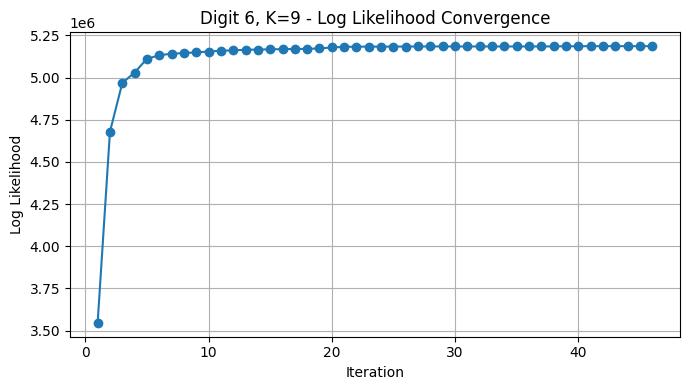

Validation Average Log Likelihood: 1631.4614

Best K for Digit 6: 9

Selecting K for Digit 3

Training GMM: Digit 3, K=3
Digit 3, K=3 | Iteration 1/70 | Log Likelihood: 3245748.3246
Digit 3, K=3 | Iteration 2/70 | Log Likelihood: 3787841.6731
Digit 3, K=3 | Iteration 3/70 | Log Likelihood: 3981552.7978
Digit 3, K=3 | Iteration 4/70 | Log Likelihood: 4012735.5350
Digit 3, K=3 | Iteration 5/70 | Log Likelihood: 4029441.6801
Digit 3, K=3 | Iteration 6/70 | Log Likelihood: 4047364.4292
Digit 3, K=3 | Iteration 7/70 | Log Likelihood: 4069354.7491
Digit 3, K=3 | Iteration 8/70 | Log Likelihood: 4082865.2964
Digit 3, K=3 | Iteration 9/70 | Log Likelihood: 4104727.8475
Digit 3, K=3 | Iteration 10/70 | Log Likelihood: 4130864.5573
Digit 3, K=3 | Iteration 11/70 | Log Likelihood: 4162162.8622
Digit 3, K=3 | Iteration 12/70 | Log Likelihood: 4182943.4504
Digit 3, K=3 | Iteration 13/70 | Log Likelihood: 4190083.4947
Digit 3, K=3 | Iteration 14/70 | Log Likelihood: 4193903.6333
Digit 3, K=3 | Itera

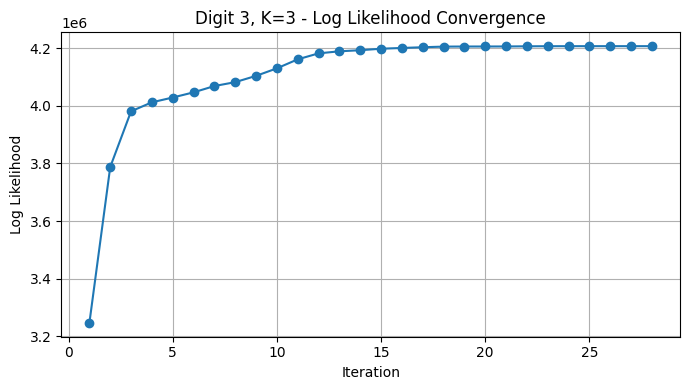

Validation Average Log Likelihood: 1237.2514

Training GMM: Digit 3, K=5
Digit 3, K=5 | Iteration 1/70 | Log Likelihood: 3290201.9032
Digit 3, K=5 | Iteration 2/70 | Log Likelihood: 3995501.8377
Digit 3, K=5 | Iteration 3/70 | Log Likelihood: 4299118.2151
Digit 3, K=5 | Iteration 4/70 | Log Likelihood: 4363440.7909
Digit 3, K=5 | Iteration 5/70 | Log Likelihood: 4405654.0243
Digit 3, K=5 | Iteration 6/70 | Log Likelihood: 4421879.6436
Digit 3, K=5 | Iteration 7/70 | Log Likelihood: 4444351.5092
Digit 3, K=5 | Iteration 8/70 | Log Likelihood: 4467030.6673
Digit 3, K=5 | Iteration 9/70 | Log Likelihood: 4487163.2540
Digit 3, K=5 | Iteration 10/70 | Log Likelihood: 4494388.4698
Digit 3, K=5 | Iteration 11/70 | Log Likelihood: 4502837.2014
Digit 3, K=5 | Iteration 12/70 | Log Likelihood: 4512513.8129
Digit 3, K=5 | Iteration 13/70 | Log Likelihood: 4518120.0515
Digit 3, K=5 | Iteration 14/70 | Log Likelihood: 4520772.8964
Digit 3, K=5 | Iteration 15/70 | Log Likelihood: 4522992.3723
Digit 

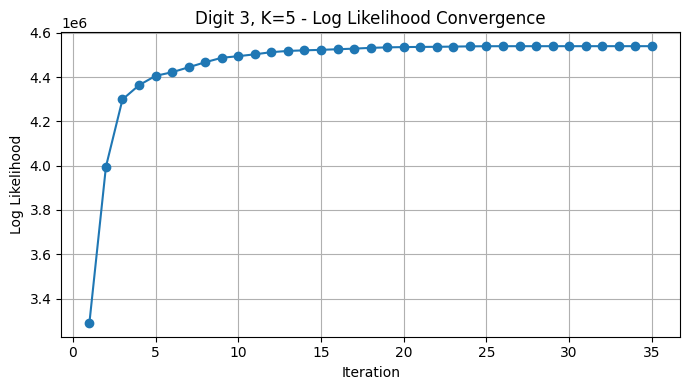

Validation Average Log Likelihood: 1354.4087

Training GMM: Digit 3, K=9
Digit 3, K=9 | Iteration 1/70 | Log Likelihood: 3305943.2039
Digit 3, K=9 | Iteration 2/70 | Log Likelihood: 4184184.4394
Digit 3, K=9 | Iteration 3/70 | Log Likelihood: 4507970.0421
Digit 3, K=9 | Iteration 4/70 | Log Likelihood: 4619440.9482
Digit 3, K=9 | Iteration 5/70 | Log Likelihood: 4652589.8602
Digit 3, K=9 | Iteration 6/70 | Log Likelihood: 4674021.1272
Digit 3, K=9 | Iteration 7/70 | Log Likelihood: 4692553.5299
Digit 3, K=9 | Iteration 8/70 | Log Likelihood: 4708322.1190
Digit 3, K=9 | Iteration 9/70 | Log Likelihood: 4714900.2954
Digit 3, K=9 | Iteration 10/70 | Log Likelihood: 4717233.2994
Digit 3, K=9 | Iteration 11/70 | Log Likelihood: 4718428.3568
Digit 3, K=9 | Iteration 12/70 | Log Likelihood: 4718613.6293
Digit 3, K=9 | Iteration 13/70 | Log Likelihood: 4718736.1456
Digit 3, K=9 | Iteration 14/70 | Log Likelihood: 4718738.4451
Digit 3, K=9 | Iteration 15/70 | Log Likelihood: 4718742.9414
Digit 

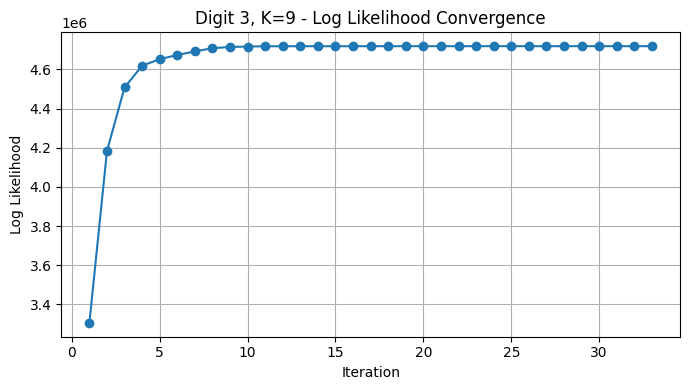

Validation Average Log Likelihood: 1358.4818

Best K for Digit 3: 9

Selecting K for Digit 8

Training GMM: Digit 8, K=3
Digit 8, K=3 | Iteration 1/70 | Log Likelihood: 3280902.0372
Digit 8, K=3 | Iteration 2/70 | Log Likelihood: 3772099.4274
Digit 8, K=3 | Iteration 3/70 | Log Likelihood: 3986057.0717
Digit 8, K=3 | Iteration 4/70 | Log Likelihood: 4025114.8740
Digit 8, K=3 | Iteration 5/70 | Log Likelihood: 4050517.6085
Digit 8, K=3 | Iteration 6/70 | Log Likelihood: 4058315.7257
Digit 8, K=3 | Iteration 7/70 | Log Likelihood: 4075189.7541
Digit 8, K=3 | Iteration 8/70 | Log Likelihood: 4126737.1549
Digit 8, K=3 | Iteration 9/70 | Log Likelihood: 4199555.3327
Digit 8, K=3 | Iteration 10/70 | Log Likelihood: 4218825.2808
Digit 8, K=3 | Iteration 11/70 | Log Likelihood: 4233316.8309
Digit 8, K=3 | Iteration 12/70 | Log Likelihood: 4240482.1891
Digit 8, K=3 | Iteration 13/70 | Log Likelihood: 4241261.1279
Digit 8, K=3 | Iteration 14/70 | Log Likelihood: 4241380.6593
Digit 8, K=3 | Itera

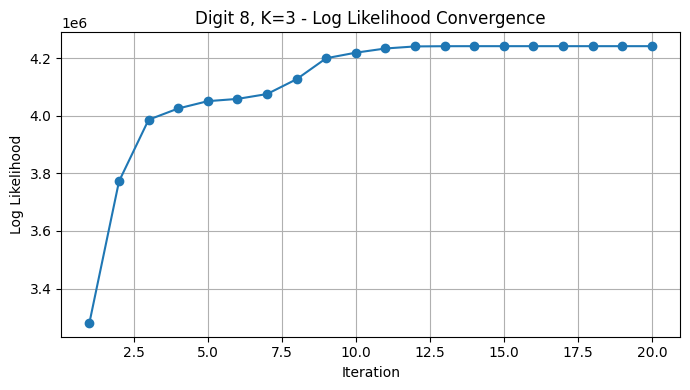

Validation Average Log Likelihood: 1383.4025

Training GMM: Digit 8, K=5
Digit 8, K=5 | Iteration 1/70 | Log Likelihood: 3260943.3602
Digit 8, K=5 | Iteration 2/70 | Log Likelihood: 4100037.8774
Digit 8, K=5 | Iteration 3/70 | Log Likelihood: 4369092.4564
Digit 8, K=5 | Iteration 4/70 | Log Likelihood: 4465768.0346
Digit 8, K=5 | Iteration 5/70 | Log Likelihood: 4495328.6227
Digit 8, K=5 | Iteration 6/70 | Log Likelihood: 4509101.8451
Digit 8, K=5 | Iteration 7/70 | Log Likelihood: 4513739.3248
Digit 8, K=5 | Iteration 8/70 | Log Likelihood: 4519780.1579
Digit 8, K=5 | Iteration 9/70 | Log Likelihood: 4523984.7039
Digit 8, K=5 | Iteration 10/70 | Log Likelihood: 4525895.7045
Digit 8, K=5 | Iteration 11/70 | Log Likelihood: 4527641.2960
Digit 8, K=5 | Iteration 12/70 | Log Likelihood: 4529138.4623
Digit 8, K=5 | Iteration 13/70 | Log Likelihood: 4531433.6622
Digit 8, K=5 | Iteration 14/70 | Log Likelihood: 4532974.0787
Digit 8, K=5 | Iteration 15/70 | Log Likelihood: 4533017.4780
Digit 

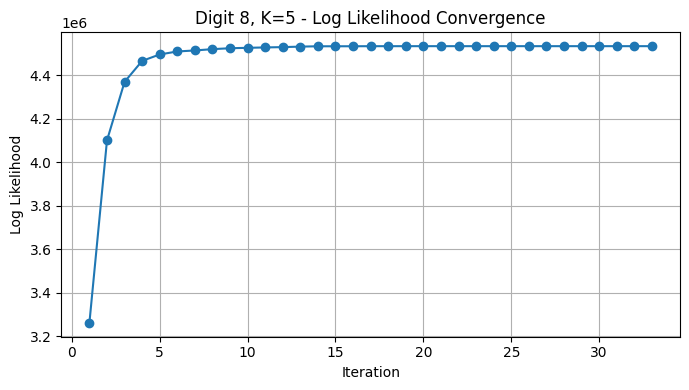

Validation Average Log Likelihood: 1510.2315

Training GMM: Digit 8, K=9
Digit 8, K=9 | Iteration 1/70 | Log Likelihood: 3320785.4059
Digit 8, K=9 | Iteration 2/70 | Log Likelihood: 4178209.2464
Digit 8, K=9 | Iteration 3/70 | Log Likelihood: 4427590.5625
Digit 8, K=9 | Iteration 4/70 | Log Likelihood: 4472764.0857
Digit 8, K=9 | Iteration 5/70 | Log Likelihood: 4493635.1103
Digit 8, K=9 | Iteration 6/70 | Log Likelihood: 4506076.1167
Digit 8, K=9 | Iteration 7/70 | Log Likelihood: 4509606.5072
Digit 8, K=9 | Iteration 8/70 | Log Likelihood: 4510549.1586
Digit 8, K=9 | Iteration 9/70 | Log Likelihood: 4511088.9433
Digit 8, K=9 | Iteration 10/70 | Log Likelihood: 4511580.3810
Digit 8, K=9 | Iteration 11/70 | Log Likelihood: 4511700.4863
Digit 8, K=9 | Iteration 12/70 | Log Likelihood: 4511776.7155
Digit 8, K=9 | Iteration 13/70 | Log Likelihood: 4511808.0870
Digit 8, K=9 | Iteration 14/70 | Log Likelihood: 4511894.3527
Digit 8, K=9 | Iteration 15/70 | Log Likelihood: 4512240.6034
Digit 

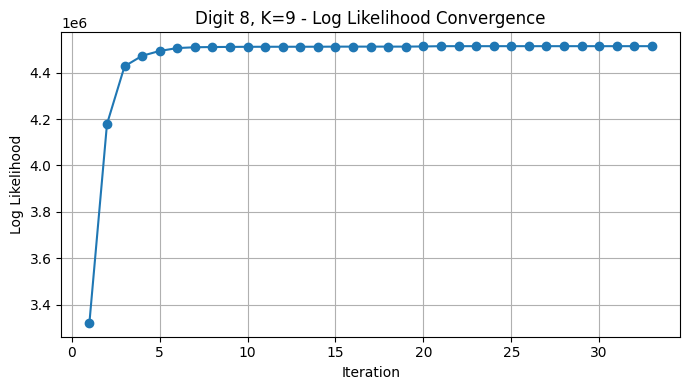

Validation Average Log Likelihood: 1457.1094

Best K for Digit 8: 5

Final GMM Training: Digit 6, K=9
Final Digit 6, K=9 | Iteration 1/70 | Log Likelihood: 4501725.3857
Final Digit 6, K=9 | Iteration 2/70 | Log Likelihood: 5981443.8443
Final Digit 6, K=9 | Iteration 3/70 | Log Likelihood: 6360790.9373
Final Digit 6, K=9 | Iteration 4/70 | Log Likelihood: 6429860.6807
Final Digit 6, K=9 | Iteration 5/70 | Log Likelihood: 6452374.1393
Final Digit 6, K=9 | Iteration 6/70 | Log Likelihood: 6465140.7102
Final Digit 6, K=9 | Iteration 7/70 | Log Likelihood: 6473821.2862
Final Digit 6, K=9 | Iteration 8/70 | Log Likelihood: 6482200.6584
Final Digit 6, K=9 | Iteration 9/70 | Log Likelihood: 6484288.4195
Final Digit 6, K=9 | Iteration 10/70 | Log Likelihood: 6485676.9234
Final Digit 6, K=9 | Iteration 11/70 | Log Likelihood: 6486241.1766
Final Digit 6, K=9 | Iteration 12/70 | Log Likelihood: 6486548.2981
Final Digit 6, K=9 | Iteration 13/70 | Log Likelihood: 6486615.5723
Final Digit 6, K=9 | It

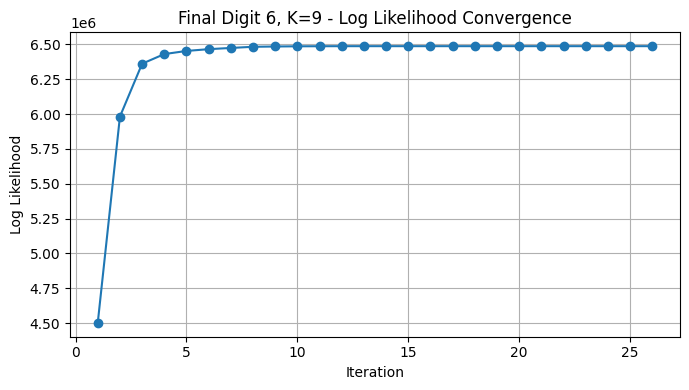


Final GMM Training: Digit 3, K=9
Final Digit 3, K=9 | Iteration 1/70 | Log Likelihood: 3984646.7197
Final Digit 3, K=9 | Iteration 2/70 | Log Likelihood: 5172960.8848
Final Digit 3, K=9 | Iteration 3/70 | Log Likelihood: 5597254.4196
Final Digit 3, K=9 | Iteration 4/70 | Log Likelihood: 5736491.4682
Final Digit 3, K=9 | Iteration 5/70 | Log Likelihood: 5799061.9860
Final Digit 3, K=9 | Iteration 6/70 | Log Likelihood: 5847120.3204
Final Digit 3, K=9 | Iteration 7/70 | Log Likelihood: 5877563.2739
Final Digit 3, K=9 | Iteration 8/70 | Log Likelihood: 5898039.6600
Final Digit 3, K=9 | Iteration 9/70 | Log Likelihood: 5914500.2960
Final Digit 3, K=9 | Iteration 10/70 | Log Likelihood: 5921010.4278
Final Digit 3, K=9 | Iteration 11/70 | Log Likelihood: 5926573.4220
Final Digit 3, K=9 | Iteration 12/70 | Log Likelihood: 5931399.6993
Final Digit 3, K=9 | Iteration 13/70 | Log Likelihood: 5935554.8538
Final Digit 3, K=9 | Iteration 14/70 | Log Likelihood: 5937389.3217
Final Digit 3, K=9 | It

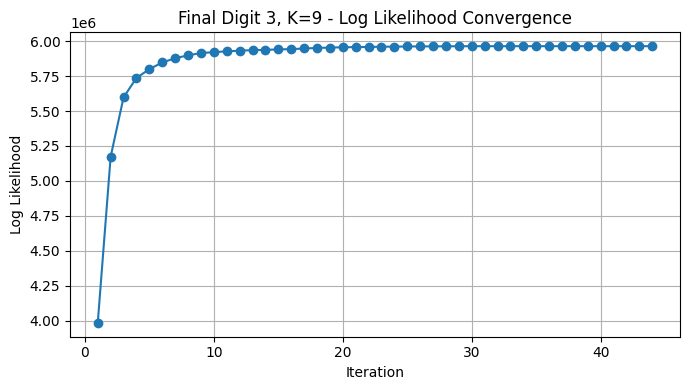


Final GMM Training: Digit 8, K=5
Final Digit 8, K=5 | Iteration 1/70 | Log Likelihood: 4138374.6134
Final Digit 8, K=5 | Iteration 2/70 | Log Likelihood: 4841168.7012
Final Digit 8, K=5 | Iteration 3/70 | Log Likelihood: 5385376.3750
Final Digit 8, K=5 | Iteration 4/70 | Log Likelihood: 5606582.4210
Final Digit 8, K=5 | Iteration 5/70 | Log Likelihood: 5664661.2422
Final Digit 8, K=5 | Iteration 6/70 | Log Likelihood: 5683991.7035
Final Digit 8, K=5 | Iteration 7/70 | Log Likelihood: 5701940.4978
Final Digit 8, K=5 | Iteration 8/70 | Log Likelihood: 5708851.4800
Final Digit 8, K=5 | Iteration 9/70 | Log Likelihood: 5715545.8037
Final Digit 8, K=5 | Iteration 10/70 | Log Likelihood: 5719274.4123
Final Digit 8, K=5 | Iteration 11/70 | Log Likelihood: 5720243.1226
Final Digit 8, K=5 | Iteration 12/70 | Log Likelihood: 5720427.2382
Final Digit 8, K=5 | Iteration 13/70 | Log Likelihood: 5720586.1291
Final Digit 8, K=5 | Iteration 14/70 | Log Likelihood: 5720597.9646
Final Digit 8, K=5 | It

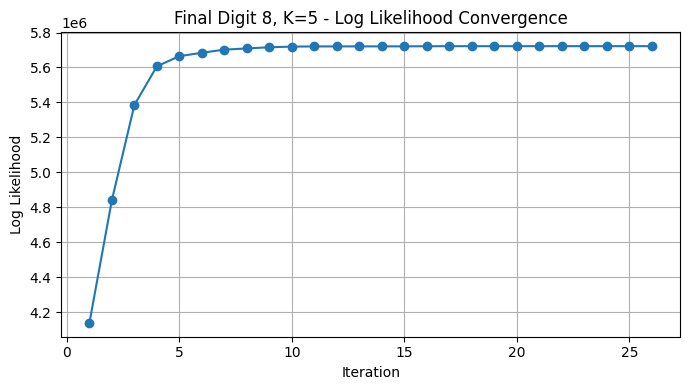

In [15]:
best_K = {}
validation_scores = {}

for digit in digits:

    print(f"\nSelecting K for Digit {digit}")

    scores = []

    for K in K_values:

        print(f"\nTraining GMM: Digit {digit}, K={K}")

        model = GMM(K, max_iter)

        model.fit(
            train_data[digit],
            label=f"Digit {digit}, K={K}"
        )

        validation_score = model.predict_score(
            validation_data[digit]
        )

        scores.append(validation_score)

        print(
            f"Validation Average Log Likelihood: "
            f"{validation_score:.4f}"
        )

    best_index = np.argmax(scores)

    best_K[digit] = K_values[best_index]
    validation_scores[digit] = scores

    print(
        f"\nBest K for Digit {digit}: "
        f"{best_K[digit]}"
    )

models = {}

for digit in digits:

    K = best_K[digit]

    print(f"\nFinal GMM Training: Digit {digit}, K={K}")

    models[digit] = GMM(K, max_iter)

    models[digit].fit(
        data[digit]['development'],
        label=f"Final Digit {digit}, K={K}"
    )


Classification Accuracy: 92.52793296089385 %

Confusion Matrix:
[[918   4  29]
 [  4 876  98]
 [ 16  63 856]]


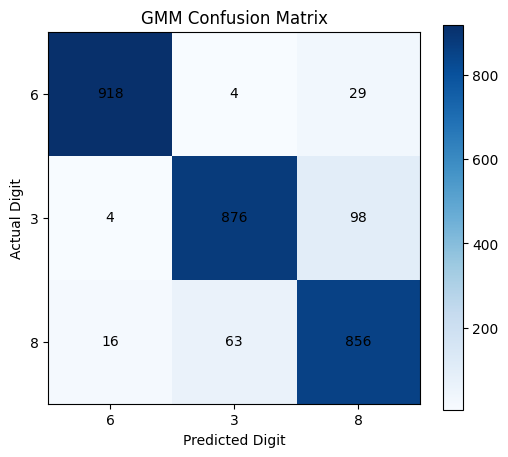

In [16]:
X_test = np.vstack([
    test_data[digit] for digit in digits
])

y_test = np.concatenate([
    np.full(len(test_data[digit]), digit)
    for digit in digits
])

scores = []

for digit in digits:

    class_score = models[digit].score_samples(X_test)

    # Include class prior probability
    prior = len(data[digit]['development']) / sum(
        len(data[d]['development']) for d in digits
    )

    class_score = class_score + np.log(prior)

    scores.append(class_score)

scores = np.array(scores).T

predicted_indices = np.argmax(scores, axis=1)

y_pred = np.array(digits)[predicted_indices]

accuracy = np.mean(y_test == y_pred) * 100

print("\nClassification Accuracy:", accuracy, "%")

cm = np.zeros(
    (len(digits), len(digits)),
    dtype=int
)

for i, actual in enumerate(digits):

    for j, predicted in enumerate(digits):

        cm[i, j] = np.sum(
            (y_test == actual) &
            (y_pred == predicted)
        )

print("\nConfusion Matrix:")
print(cm)


plt.figure(figsize=(6, 5))

plt.imshow(cm, cmap='Blues')

plt.xticks(range(len(digits)), digits)
plt.yticks(range(len(digits)), digits)

plt.xlabel("Predicted Digit")
plt.ylabel("Actual Digit")
plt.title("GMM Confusion Matrix")

for i in range(len(digits)):
    for j in range(len(digits)):
        plt.text(
            j, i,
            str(cm[i, j]),
            ha='center',
            va='center'
        )

plt.colorbar()
plt.show()

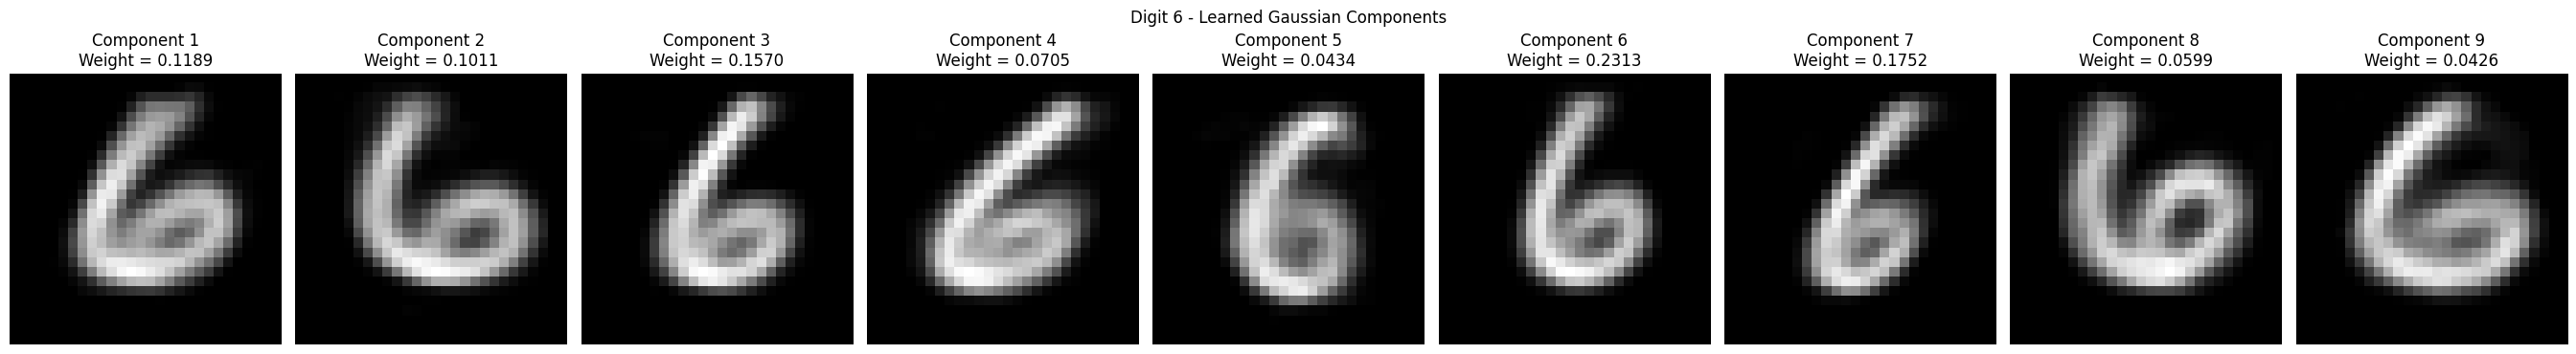

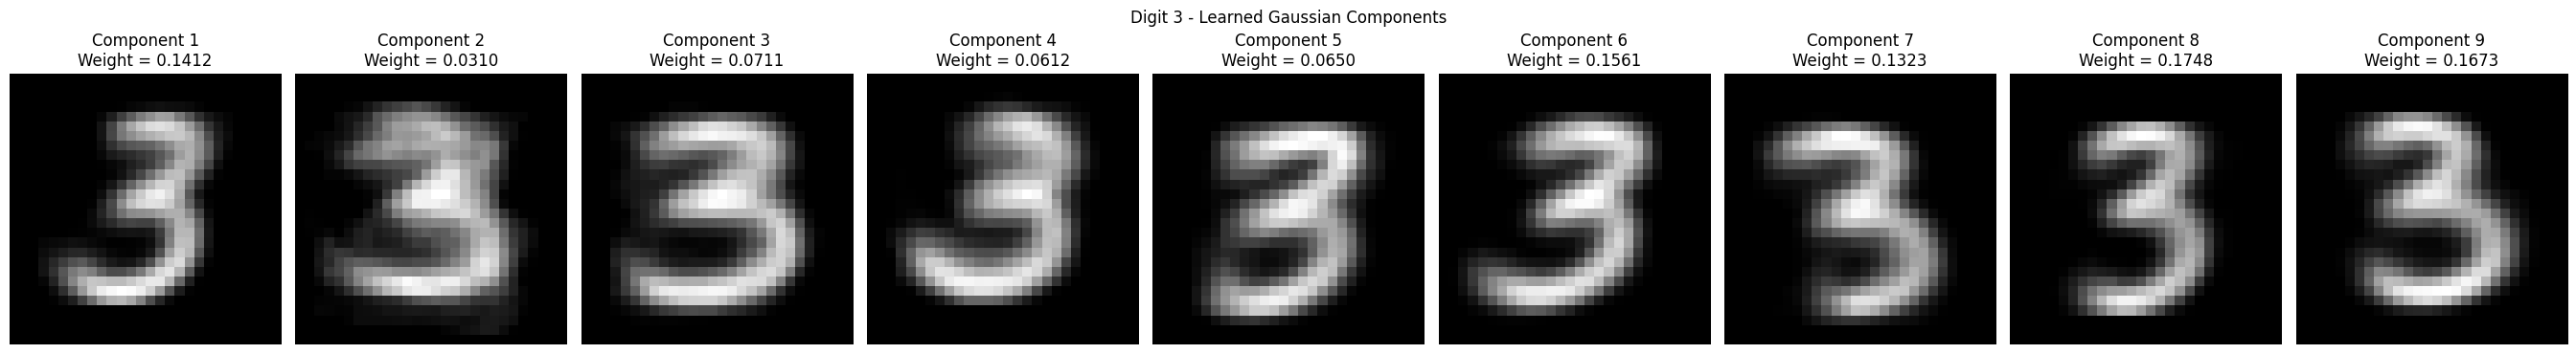

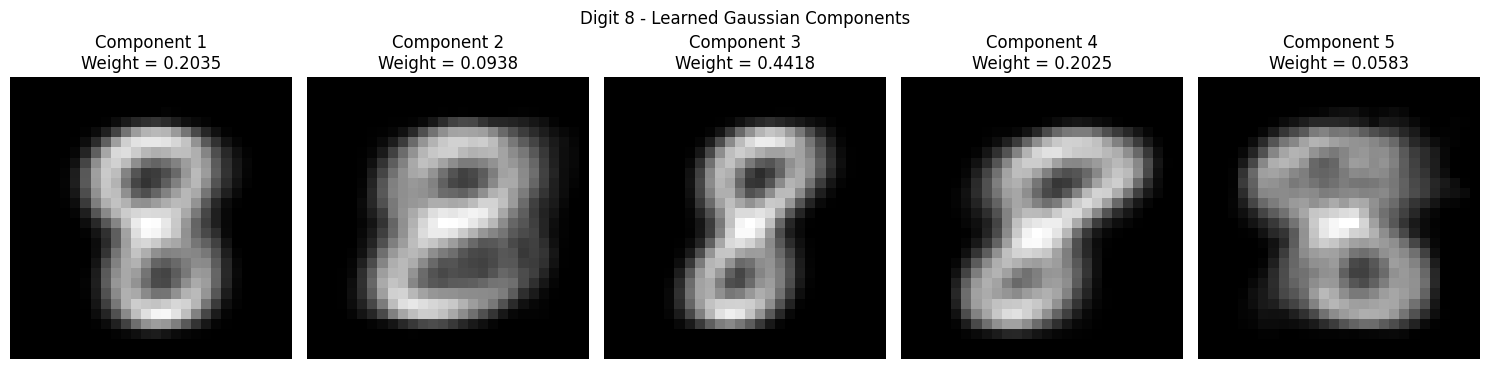


Total Misclassified Images: 214


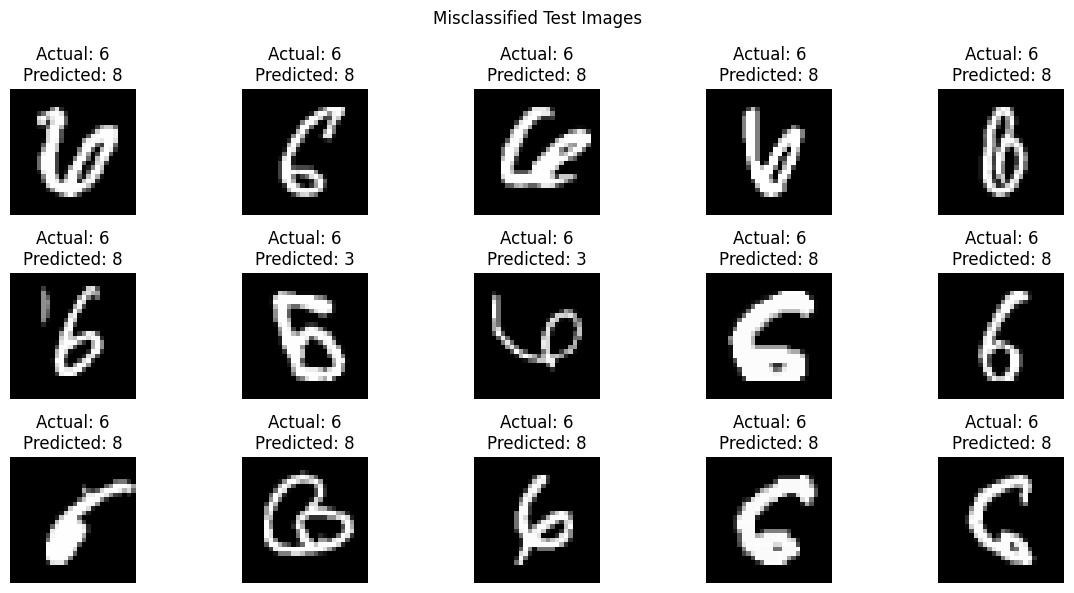

In [17]:
for digit in digits:

    model = models[digit]

    K = model.K

    fig, axes = plt.subplots(
        1,
        K,
        figsize=(3 * K, 4)
    )

    if K == 1:
        axes = [axes]

    fig.suptitle(
        f"Digit {digit} - Learned Gaussian Components"
    )

    for k in range(K):

        axes[k].imshow(
            model.means[k].reshape(28, 28),
            cmap='gray'
        )

        axes[k].set_title(
            f"Component {k + 1}\n"
            f"Weight = {model.weights[k]:.4f}"
        )

        axes[k].axis('off')

    plt.tight_layout()
    plt.show()

wrong_indices = np.where(y_test != y_pred)[0]

print("\nTotal Misclassified Images:", len(wrong_indices))

count = min(15, len(wrong_indices))

if count > 0:

    plt.figure(figsize=(12, 6))

    for i in range(count):

        index = wrong_indices[i]

        plt.subplot(3, 5, i + 1)

        plt.imshow(
            X_test[index].reshape(28, 28),
            cmap='gray'
        )

        plt.title(
            f"Actual: {y_test[index]}\n"
            f"Predicted: {y_pred[index]}"
        )

        plt.axis('off')

    plt.suptitle("Misclassified Test Images")
    plt.tight_layout()
    plt.show()
